# TAREA 2 · SEMANA 10
# Segmentación de clientes con K-Means

**Reporte de proyecto en Jupyter · 6 horas de referencia**

Estudiante: ____________________  
Curso / docente: ____________________  
Fecha: ____________________

Este cuaderno sustituye el informe e incluye teoría, diagrama de flujo, implementación, resultados ejecutados y conclusiones. Los datos son sintéticos y reproducibles.

## Preparación
Abrir en Jupyter o Google Colab. Ejecutar todas las celdas en orden. Si faltan bibliotecas, instalar requirements.txt o descomentar la siguiente celda.

In [1]:
%matplotlib inline
# %pip install numpy matplotlib scikit-learn scipy tensorflow

## Objetivo y problema
Agrupar clientes ficticios por ingreso y gasto mensual sin disponer de clases previas.

## Fundamento: operaciones de la semana 10
El aprendizaje no supervisado descubre estructura sin respuesta etiquetada. Incluye agrupamiento (K-Means, DBSCAN, jerárquico), reducción de dimensión (PCA), detección de anomalías (Isolation Forest) y reglas de asociación para coocurrencias.

Clasificación y agrupamiento son distintos: la clasificación aprende categorías conocidas con etiquetas; el agrupamiento descubre grupos de similitud sin etiquetas. El número de grupo es arbitrario y no implica jerarquía ni una categoría verdadera.

K-Means minimiza distancias cuadradas a centroides. Inicializa centros, asigna cada punto al más cercano y recalcula medias, repitiendo hasta convergencia o máximo de iteraciones. Se usa k-means++ y 20 inicializaciones para reducir dependencia del inicio.

## Datos y método
180 clientes sintéticos en tres nubes de ingreso y gasto. Se estandarizan ambas variables para impedir que una escala domine. Se comparan K de 2 a 6 con silueta e inercia. La silueta va de -1 a 1: valores altos indican separación relativa. La inercia disminuye normalmente al aumentar K, por lo que no basta para elegirlo. Los grupos se describen con centroides en unidades originales.


## Diagrama de flujo de la función principal
Se dibuja con Python y queda guardado como PNG, sin servicios externos.

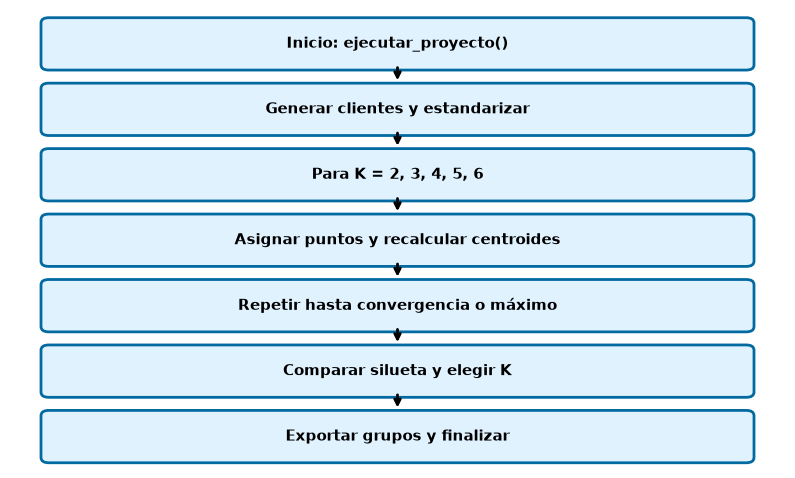

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from matplotlib.patches import FancyBboxPatch
pasos=['Inicio: ejecutar_proyecto()', 'Generar clientes y estandarizar', 'Para K = 2, 3, 4, 5, 6', 'Asignar puntos y recalcular centroides', 'Repetir hasta convergencia o máximo', 'Comparar silueta y elegir K', 'Exportar grupos y finalizar']
fig,ax=plt.subplots(figsize=(10,len(pasos)*.85)); ax.set(xlim=(0,10),ylim=(0,len(pasos)*1.25)); ax.axis('off')
for i,paso in enumerate(pasos):
    y=(len(pasos)-i-1)*1.25+.2
    ax.add_patch(FancyBboxPatch((.5,y),9,.8,boxstyle='round,pad=.1',facecolor='#e0f2fe',edgecolor='#0369a1',linewidth=2))
    ax.text(5,y+.4,paso,ha='center',va='center',fontsize=11,fontweight='bold')
    if i<len(pasos)-1:ax.annotate('',xy=(5,y-.35),xytext=(5,y),arrowprops={'arrowstyle':'->','lw':2})
plt.savefig('resultados/diagrama_flujo.png',dpi=140,bbox_inches='tight'); plt.show()


## Implementación y resultados
Las salidas siguientes proceden de ejecutar este código.

Comparación: {
  "2": {
    "silueta": 0.6883402280173071,
    "inercia": 113.60493280292644
  },
  "3": {
    "silueta": 0.815620250841377,
    "inercia": 17.162315502986836
  },
  "4": {
    "silueta": 0.750031969735312,
    "inercia": 11.022702110558216
  },
  "5": {
    "silueta": 0.6290015780454882,
    "inercia": 8.090143457900147
  },
  "6": {
    "silueta": 0.5967932190769606,
    "inercia": 6.387446492186519
  }
}
K elegido: 3 Iteraciones: 2
Grupo 0 cantidad 60 centro ingreso/gasto [4473.73538457 1403.65700285]
Grupo 1 cantidad 60 centro ingreso/gasto [8078.47042634  891.73769541]
Grupo 2 cantidad 60 centro ingreso/gasto [1793.5272965   342.92477926]
Grupo de nuevo cliente (4600,1500): 0


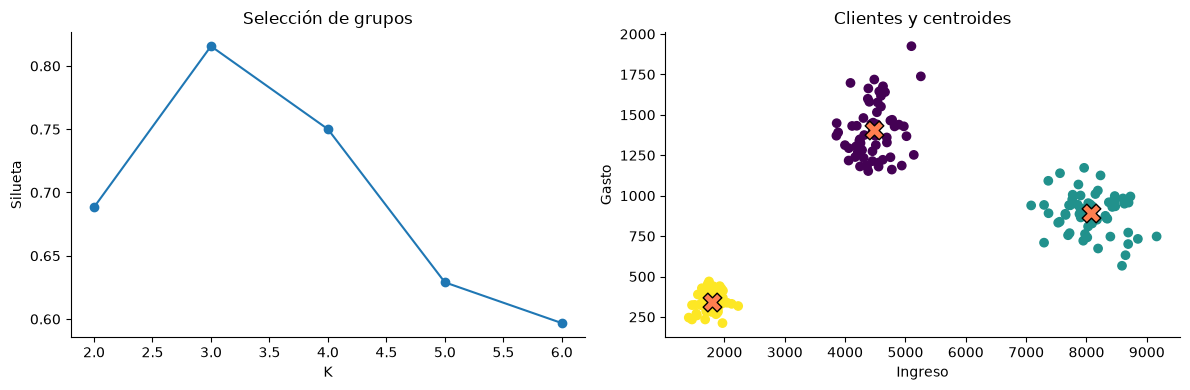

### Interpretación de la ejecución
La mejor silueta entre los candidatos corresponde a **3 grupos**, con **0.816**. Los centroides describen perfiles relativos; sus identificadores no tienen orden.

702

In [3]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

def ejecutar_proyecto():
    rng=np.random.default_rng(42)
    X=np.vstack([rng.normal([1800,350],[200,80],(60,2)),rng.normal([4500,1400],[300,180],(60,2)),rng.normal([8000,900],[400,130],(60,2))])
    np.savetxt('datos.csv',X,delimiter=',',header='ingreso,gasto',comments='')
    scaler=StandardScaler(); Z=scaler.fit_transform(X); scores={}; models={}
    for k in range(2,7):
        model=KMeans(n_clusters=k,n_init=20,random_state=42,max_iter=300).fit(Z)
        models[k]=model; scores[k]={'silueta':float(silhouette_score(Z,model.labels_)),'inercia':float(model.inertia_)}
    k=max(scores,key=lambda v:scores[v]['silueta']); model=models[k]; centers=scaler.inverse_transform(model.cluster_centers_)
    print('Comparación:',json.dumps(scores,indent=2)); print('K elegido:',k,'Iteraciones:',model.n_iter_)
    for g,center in enumerate(centers): print('Grupo',g,'cantidad',int((model.labels_==g).sum()),'centro ingreso/gasto',center)
    print('Grupo de nuevo cliente (4600,1500):',model.predict(scaler.transform([[4600,1500]]))[0])
    fig,ax=plt.subplots(1,2,figsize=(12,4)); ax[0].plot(list(scores),[v['silueta'] for v in scores.values()],'o-'); ax[0].set(xlabel='K',ylabel='Silueta',title='Selección de grupos')
    ax[1].scatter(X[:,0],X[:,1],c=model.labels_,cmap='viridis'); ax[1].scatter(centers[:,0],centers[:,1],marker='X',c='coral',s=180,edgecolor='black'); ax[1].set(xlabel='Ingreso',ylabel='Gasto',title='Clientes y centroides')
    plt.tight_layout(); plt.savefig('resultados/proyecto.png',dpi=140); plt.show()
    np.savetxt('resultados/segmentos.csv',np.c_[X,model.labels_],delimiter=',',header='ingreso,gasto,grupo',comments='')
    display(Markdown(f"### Interpretación de la ejecución\nLa mejor silueta entre los candidatos corresponde a **{k} grupos**, con **{scores[k]['silueta']:.3f}**. Los centroides describen perfiles relativos; sus identificadores no tienen orden."))
    return {'k_elegido':k,'comparacion':scores,'centros':centers.tolist()}

metricas=ejecutar_proyecto()
Path('resultados/metricas.json').write_text(json.dumps(metricas,indent=2),encoding='utf-8')


## Conclusiones, limitaciones y exploración
La estandarización equilibra las variables y la silueta apoya una selección explicable. K-Means favorece grupos compactos; es sensible a valores atípicos y puede fallar con grupos curvos o densidades diferentes. Los clientes son ficticios y no justifican decisiones comerciales reales. Explorar: quitar la estandarización o añadir un ingreso extremo y comparar los centroides.

## Referencias oficiales
- https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html